#1.Raw Data Audit

*(import libraries)*

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.3f}'.format)

print("Libraries imported successfully.")

Libraries imported successfully.


*(load dataset)*

In [ ]:
uploaded = files.upload()

file_name = next(iter(uploaded))

df_raw = pd.read_csv(file_name, compression='infer')

print("Dataset loaded successfully.")
print("File:", file_name)

Saving 5G_netops_data_100K.csv.xz to 5G_netops_data_100K.csv (1).xz
Dataset loaded successfully.
File: 5G_netops_data_100K.csv (1).xz


*(dimensions)*

In [ ]:
rows, columns = df_raw.shape

print("Number of rows:", rows)
print("Number of columns:", columns)
print("Total cells:", rows * columns)

display(df_raw.head())

Number of rows: 100000
Number of columns: 27
Total cells: 2700000


,Season,Cell Availability (%),MTTR (hours),Throughput (Mbps),Latency (ms),Packet Loss Rate (%),Call Drop Rate (%),Handover Success Rate (%),Alarm Count,Critical Alarm Count,Parameter Changes,Successful Configuration Changes (%),Data Usage (GB),User Count,Signal Strength (dBm),Jitter (ms),Connection Setup Success Rate (%),Security Incidents,Authentication Failures,Temperature (°C),Humidity (%),Weather,Issue Reported,City,State,Zip,Fault Occurrence Rate (%)
0,Winter,98.045,3.000,653.531,74.336,6.438,1.467,99.290,13,6.718,18,91.850,47.490,2442,-110.120,15.670,99.000,8,2,-6.750,28.790,Clouds,yes,Schneiderville,MN,46530,33.582
1,Fall,99.000,8.850,719.299,90.651,5.180,0.022,96.500,12,5.551,17,90.370,47.930,2146,-77.960,37.310,94.860,11,4,10.360,37.040,Clear,yes,Lake Heidiside,IN,42562,31.171
2,Winter,99.000,6.110,868.787,78.068,8.688,0.000,96.790,5,1.898,2,95.280,44.680,1453,-114.570,8.500,96.610,1,10,-7.410,27.760,Clouds,yes,Howardview,KS,34713,16.343
3,Fall,95.333,7.660,332.074,32.318,6.200,1.979,99.120,7,8.715,12,98.590,22.150,5390,-68.550,34.350,95.950,4,1,14.800,34.090,Clear,yes,West Bryan,AR,43621,41.842
4,Fall,99.000,2.820,658.490,84.256,11.800,0.190,91.400,11,6.013,18,97.800,25.800,7075,-66.000,24.200,92.640,6,0,13.090,32.050,Clouds,no,Downschester,ME,21728,29.407


*(cols amd datatypes)*

In [ ]:
column_info = pd.DataFrame({
    'Column Name': df_raw.columns,
    'Data Type': df_raw.dtypes.astype(str).values,
    'Non-Null Count': df_raw.notna().sum().values,
    'Unique Values': df_raw.nunique().values
})

display(column_info)

,Column Name,Data Type,Non-Null Count,Unique Values
0,Season,object,100000,4
1,Cell Availability (%),float64,100000,33192
2,MTTR (hours),float64,100000,951
3,Throughput (Mbps),float64,100000,99691
4,Latency (ms),float64,100000,84654
5,Packet Loss Rate (%),float64,100000,3326
6,Call Drop Rate (%),float64,100000,49740
7,Handover Success Rate (%),float64,100000,1001
8,Alarm Count,int64,100000,27
9,Critical Alarm Count,float64,100000,98580


*(categorical and numerical data)*

In [ ]:
numerical_cols = df_raw.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_cols = df_raw.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

print("\nNumerical Features:")
print(numerical_cols)

print("\nCategorical Features:")
print(categorical_cols)

Numerical columns: 22
Categorical columns: 5

Numerical Features:
['Cell Availability (%)', 'MTTR (hours)', 'Throughput (Mbps)', 'Latency (ms)', 'Packet Loss Rate (%)', 'Call Drop Rate (%)', 'Handover Success Rate (%)', 'Alarm Count', 'Critical Alarm Count', 'Parameter Changes', 'Successful Configuration Changes (%)', 'Data Usage (GB)', 'User Count', 'Signal Strength (dBm)', 'Jitter (ms)', 'Connection Setup Success Rate (%)', 'Security Incidents', 'Authentication Failures', 'Temperature (°C)', 'Humidity (%)', 'Zip', 'Fault Occurrence Rate (%)']

Categorical Features:
['Season', 'Weather', 'Issue Reported', 'City', 'State']


*(missing values)*

In [ ]:
missing_audit = pd.DataFrame({
    'Missing Count': df_raw.isnull().sum(),
    'Missing Percentage': (
        df_raw.isnull().mean() * 100
    )
})

missing_audit = missing_audit.sort_values(
    by='Missing Count',
    ascending=False
)

display(missing_audit)

print("Total missing cells:", df_raw.isnull().sum().sum())

,Missing Count,Missing Percentage
Season,0,0.000
Cell Availability (%),0,0.000
MTTR (hours),0,0.000
Throughput (Mbps),0,0.000
Latency (ms),0,0.000
Packet Loss Rate (%),0,0.000
Call Drop Rate (%),0,0.000
Handover Success Rate (%),0,0.000
Alarm Count,0,0.000
Critical Alarm Count,0,0.000


Total missing cells: 0


*(duplicate values)*

In [ ]:
exact_duplicates = df_raw.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)

print(
    "Percentage of duplicate rows:",
    round(exact_duplicates / len(df_raw) * 100, 3),
    "%"
)

Exact duplicate rows: 0
Percentage of duplicate rows: 0.0 %


(repeated locations: data from same location)

In [ ]:
location_cols = ['City', 'State', 'Zip']

if all(col in df_raw.columns for col in location_cols):
    repeated_locations = df_raw.duplicated(
        subset=location_cols
    ).sum()

    print(
        "Rows repeating a City-State-Zip combination:",
        repeated_locations
    )

Rows repeating a City-State-Zip combination: 0


*(identifing categories)*

In [ ]:
for col in categorical_cols:
    print(f"\n{'=' * 50}")
    print("Column:", col)
    print("Unique values:", df_raw[col].nunique())
    print("\nValue counts:")
    display(df_raw[col].value_counts(dropna=False).head(15))


Column: Season
Unique values: 4

Value counts:


,count
Season,
Fall,25117
Spring,25106
Winter,24941
Summer,24836



Column: Weather
Unique values: 4

Value counts:


,count
Weather,
Clouds,31392
Rain,31204
Clear,31185
Snow,6219



Column: Issue Reported
Unique values: 2

Value counts:


,count
Issue Reported,
no,50111
yes,49889



Column: City
Unique values: 38066

Value counts:


,count
City,
New Michael,89
Lake Michael,82
Port Michael,82
North Michael,80
West Michael,78
South Michael,77
Port James,70
West David,70
Michaelmouth,68



Column: State
Unique values: 59

Value counts:


,count
State,
NE,1767
ID,1757
MP,1753
SC,1752
MT,1750
GA,1749
VI,1745
MS,1743
TN,1741


# 2.Statistics

*(descriptive Stats)*

In [ ]:
display(df_raw[numerical_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
Cell Availability (%),100000.000,89.250,6.987,74.342,83.192,89.401,95.707,99.000
MTTR (hours),100000.000,5.251,2.741,0.500,2.890,5.250,7.620,10.000
Throughput (Mbps),100000.000,586.573,239.437,114.992,394.302,549.212,744.453,1283.855
Latency (ms),100000.000,79.217,36.128,4.618,49.311,77.216,105.390,175.844
Packet Loss Rate (%),100000.000,6.458,3.882,0.100,3.188,6.240,9.330,17.000
Call Drop Rate (%),100000.000,0.949,1.352,0.000,0.000,0.000,1.659,6.900
Handover Success Rate (%),100000.000,95.017,2.887,90.000,92.510,95.020,97.520,100.000
Alarm Count,100000.000,10.012,3.156,0.000,8.000,10.000,12.000,26.000
Critical Alarm Count,100000.000,6.364,2.673,0.000,4.573,6.745,8.420,13.864
Parameter Changes,100000.000,9.517,5.773,0.000,4.000,10.000,15.000,19.000


*(deviation measures)*

In [ ]:
measurement_cols = [
    col for col in numerical_cols
    if col != 'Zip'
]

descriptive_stats = pd.DataFrame(index=measurement_cols)

descriptive_stats['Mean'] = df_raw[measurement_cols].mean()
descriptive_stats['Median'] = df_raw[measurement_cols].median()

descriptive_stats['Mode'] = df_raw[measurement_cols].mode().iloc[0]

descriptive_stats['Minimum'] = df_raw[measurement_cols].min()
descriptive_stats['Maximum'] = df_raw[measurement_cols].max()

descriptive_stats['Range'] = (
    descriptive_stats['Maximum'] -
    descriptive_stats['Minimum']
)

descriptive_stats['Q1'] = df_raw[measurement_cols].quantile(0.25)
descriptive_stats['Q3'] = df_raw[measurement_cols].quantile(0.75)

descriptive_stats['IQR'] = (
    descriptive_stats['Q3'] - descriptive_stats['Q1']
)

descriptive_stats['Quartile Deviation'] = (
    descriptive_stats['IQR'] / 2
)

descriptive_stats['Mean Absolute Deviation'] = (
    df_raw[measurement_cols]
    .sub(df_raw[measurement_cols].mean())
    .abs()
    .mean()
)

descriptive_stats['Standard Deviation'] = (
    df_raw[measurement_cols].std()
)

display(descriptive_stats.round(3))

,Mean,Median,Mode,Minimum,Maximum,Range,Q1,Q3,IQR,Quartile Deviation,Mean Absolute Deviation,Standard Deviation
Cell Availability (%),89.250,89.401,99.000,74.342,99.000,24.658,83.192,95.706,12.514,6.257,6.094,6.987
MTTR (hours),5.251,5.250,5.300,0.500,10.000,9.500,2.890,7.620,4.730,2.365,2.372,2.741
Throughput (Mbps),586.573,549.212,591.883,114.992,1283.856,1168.864,394.302,744.453,350.151,175.075,196.963,239.437
Latency (ms),79.217,77.216,90.284,4.618,175.844,171.226,49.311,105.390,56.079,28.039,30.291,36.128
Packet Loss Rate (%),6.458,6.240,2.850,0.100,17.000,16.900,3.188,9.330,6.142,3.071,3.271,3.882
Call Drop Rate (%),0.949,0.000,0.000,0.000,6.900,6.900,0.000,1.659,1.659,0.830,1.099,1.352
Handover Success Rate (%),95.017,95.020,97.100,90.000,100.000,10.000,92.510,97.520,5.010,2.505,2.500,2.887
Alarm Count,10.012,10.000,9.000,0.000,26.000,26.000,8.000,12.000,4.000,2.000,2.499,3.156
Critical Alarm Count,6.364,6.745,0.000,0.000,13.864,13.864,4.573,8.420,3.847,1.923,2.193,2.673
Parameter Changes,9.517,10.000,2.000,0.000,19.000,19.000,4.000,15.000,11.000,5.500,5.009,5.773


*(outlier detection- IQR method)*

In [ ]:
outlier_results = []

for col in measurement_cols:
    q1 = df_raw[col].quantile(0.25)
    q3 = df_raw[col].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (df_raw[col] < lower_bound) |
        (df_raw[col] > upper_bound)
    )

    outlier_count = outlier_mask.sum()

    outlier_results.append({
        'Feature': col,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': outlier_count,
        'Outlier Percentage': (
            outlier_count / len(df_raw) * 100
        )
    })

outlier_audit = pd.DataFrame(outlier_results)

outlier_audit = outlier_audit.sort_values(
    by='Outlier Count',
    ascending=False
)

display(outlier_audit.round(3))

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
17,Authentication Failures,4.000,18.000,14.000,-17.000,39.000,8741,8.741
5,Call Drop Rate (%),0.000,1.659,1.659,-2.489,4.148,3835,3.835
7,Alarm Count,8.000,12.000,4.000,2.000,18.000,739,0.739
20,Fault Occurrence Rate (%),28.339,48.152,19.812,-1.379,77.870,10,0.010
2,Throughput (Mbps),394.302,744.453,350.151,-130.924,1269.679,2,0.002
4,Packet Loss Rate (%),3.188,9.330,6.142,-6.026,18.544,0,0.000
3,Latency (ms),49.311,105.390,56.079,-34.807,189.508,0,0.000
1,MTTR (hours),2.890,7.620,4.730,-4.205,14.715,0,0.000
0,Cell Availability (%),83.192,95.706,12.514,64.420,114.478,0,0.000
9,Parameter Changes,4.000,15.000,11.000,-12.500,31.500,0,0.000


*(feature check)- name based only*

In [ ]:
required_features = [
    'Network node ID',
    'Cell tower ID',
    'Timestamp',
    'Signal strength',
    'Bandwidth utilization',
    'Packet loss',
    'Latency',
    'Throughput',
    'Number of connected users',
    'Error count',
    'Maintenance history',
    'Fault label'
]

available_columns = df_raw.columns.tolist()

feature_check = pd.DataFrame({
    'Required Feature': required_features,
    'Availability': [
        'Available' if any(
            feature.lower() in col.lower()
            for col in available_columns
        ) else 'Not directly available'
        for feature in required_features
    ]
})

display(feature_check)

,Required Feature,Availability
0,Network node ID,Not directly available
1,Cell tower ID,Not directly available
2,Timestamp,Not directly available
3,Signal strength,Available
4,Bandwidth utilization,Not directly available
5,Packet loss,Available
6,Latency,Available
7,Throughput,Available
8,Number of connected users,Not directly available
9,Error count,Not directly available


*(corelation)*

In [ ]:
# Exclude the ZIP identifier from correlation analysis.
correlation_cols = [
    col for col in measurement_cols
    if pd.api.types.is_numeric_dtype(df_raw[col])
]

correlation_matrix = df_raw[correlation_cols].corr()

display(correlation_matrix.round(3))

,Cell Availability (%),MTTR (hours),Throughput (Mbps),Latency (ms),Packet Loss Rate (%),Call Drop Rate (%),Handover Success Rate (%),Alarm Count,Critical Alarm Count,Parameter Changes,Successful Configuration Changes (%),Data Usage (GB),User Count,Signal Strength (dBm),Jitter (ms),Connection Setup Success Rate (%),Security Incidents,Authentication Failures,Temperature (°C),Humidity (%),Fault Occurrence Rate (%)
Cell Availability (%),1.000,-0.035,0.062,-0.003,-0.005,-0.024,-0.001,-0.087,-0.080,-0.001,0.031,0.000,-0.001,0.003,-0.004,-0.001,-0.002,-0.002,-0.002,-0.005,-0.062
MTTR (hours),-0.035,1.000,0.000,0.003,-0.002,0.012,-0.009,0.003,0.003,-0.000,0.001,-0.005,0.005,-0.011,0.004,-0.001,0.002,-0.003,0.001,0.002,0.001
Throughput (Mbps),0.062,0.000,1.000,-0.189,-0.238,-0.367,0.001,-0.002,-0.958,0.001,-0.000,0.001,0.118,0.004,-0.006,0.001,0.004,-0.348,0.093,0.062,-0.917
Latency (ms),-0.003,0.003,-0.189,1.000,0.095,0.142,-0.000,-0.006,0.189,0.001,-0.003,0.001,-0.003,-0.004,0.041,-0.009,0.001,0.197,0.089,0.103,0.224
Packet Loss Rate (%),-0.005,-0.002,-0.238,0.095,1.000,0.149,-0.002,-0.001,0.235,-0.001,-0.001,-0.001,-0.002,-0.006,0.005,0.002,-0.002,0.189,-0.050,-0.036,0.259
Call Drop Rate (%),-0.024,0.012,-0.367,0.142,0.149,1.000,-0.001,0.056,0.484,0.014,0.000,-0.005,-0.027,-0.006,0.004,-0.057,0.002,0.281,-0.083,-0.058,0.463
Handover Success Rate (%),-0.001,-0.009,0.001,-0.000,-0.002,-0.001,1.000,-0.004,-0.003,0.002,-0.001,-0.001,0.003,0.003,-0.001,-0.003,-0.000,0.006,0.000,-0.004,0.000
Alarm Count,-0.087,0.003,-0.002,-0.006,-0.001,0.056,-0.004,1.000,0.246,-0.001,-0.004,-0.003,0.002,0.002,-0.001,0.005,-0.002,-0.003,-0.000,0.001,0.136
Critical Alarm Count,-0.080,0.003,-0.958,0.189,0.235,0.484,-0.003,0.246,1.000,0.045,-0.001,-0.002,-0.109,-0.004,0.006,-0.011,-0.003,0.352,-0.095,-0.063,0.930
Parameter Changes,-0.001,-0.000,0.001,0.001,-0.001,0.014,0.002,-0.001,0.045,1.000,0.003,-0.001,0.005,0.006,0.004,-0.000,0.001,-0.001,-0.005,-0.000,0.024


In [ ]:
target = 'Fault Occurrence Rate (%)'

if target in correlation_matrix.columns:
    target_correlations = (
        correlation_matrix[target]
        .drop(target)
        .sort_values(key=abs, ascending=False)
    )

    display(
        target_correlations.to_frame(
            name='Correlation with Fault Occurrence Rate'
        )
    )

,Correlation with Fault Occurrence Rate
Critical Alarm Count,0.930
Throughput (Mbps),-0.917
Authentication Failures,0.635
Call Drop Rate (%),0.463
Packet Loss Rate (%),0.259
Latency (ms),0.224
Security Incidents,0.139
Alarm Count,0.136
Temperature (°C),-0.121
User Count,-0.092


In [ ]:
# Keep the raw data unchanged for subsequent comparisons.
df = df_raw.copy(deep=True)

print("Raw dataset shape:", df_raw.shape)
print("Working copy shape:", df.shape)

print(
    "Raw data and working copy initially identical:",
    df_raw.equals(df)
)

Raw dataset shape: (100000, 27)
Working copy shape: (100000, 27)
Raw data and working copy initially identical: True


# 3. EDA

In [ ]:
# Select representative numerical features for visualization

plot_cols = [
    'Cell Availability (%)',
    'Throughput (Mbps)',
    'Latency (ms)',
    'Packet Loss Rate (%)',
    'Call Drop Rate (%)',
    'Critical Alarm Count',
    'Signal Strength (dBm)',
    'User Count',
    'Fault Occurrence Rate (%)'
]

# Confirm all selected columns exist
plot_cols = [col for col in plot_cols if col in df.columns]

print("Selected features:", len(plot_cols))
print(plot_cols)

Selected features: 9
['Cell Availability (%)', 'Throughput (Mbps)', 'Latency (ms)', 'Packet Loss Rate (%)', 'Call Drop Rate (%)', 'Critical Alarm Count', 'Signal Strength (dBm)', 'User Count', 'Fault Occurrence Rate (%)']


*(histogram)*

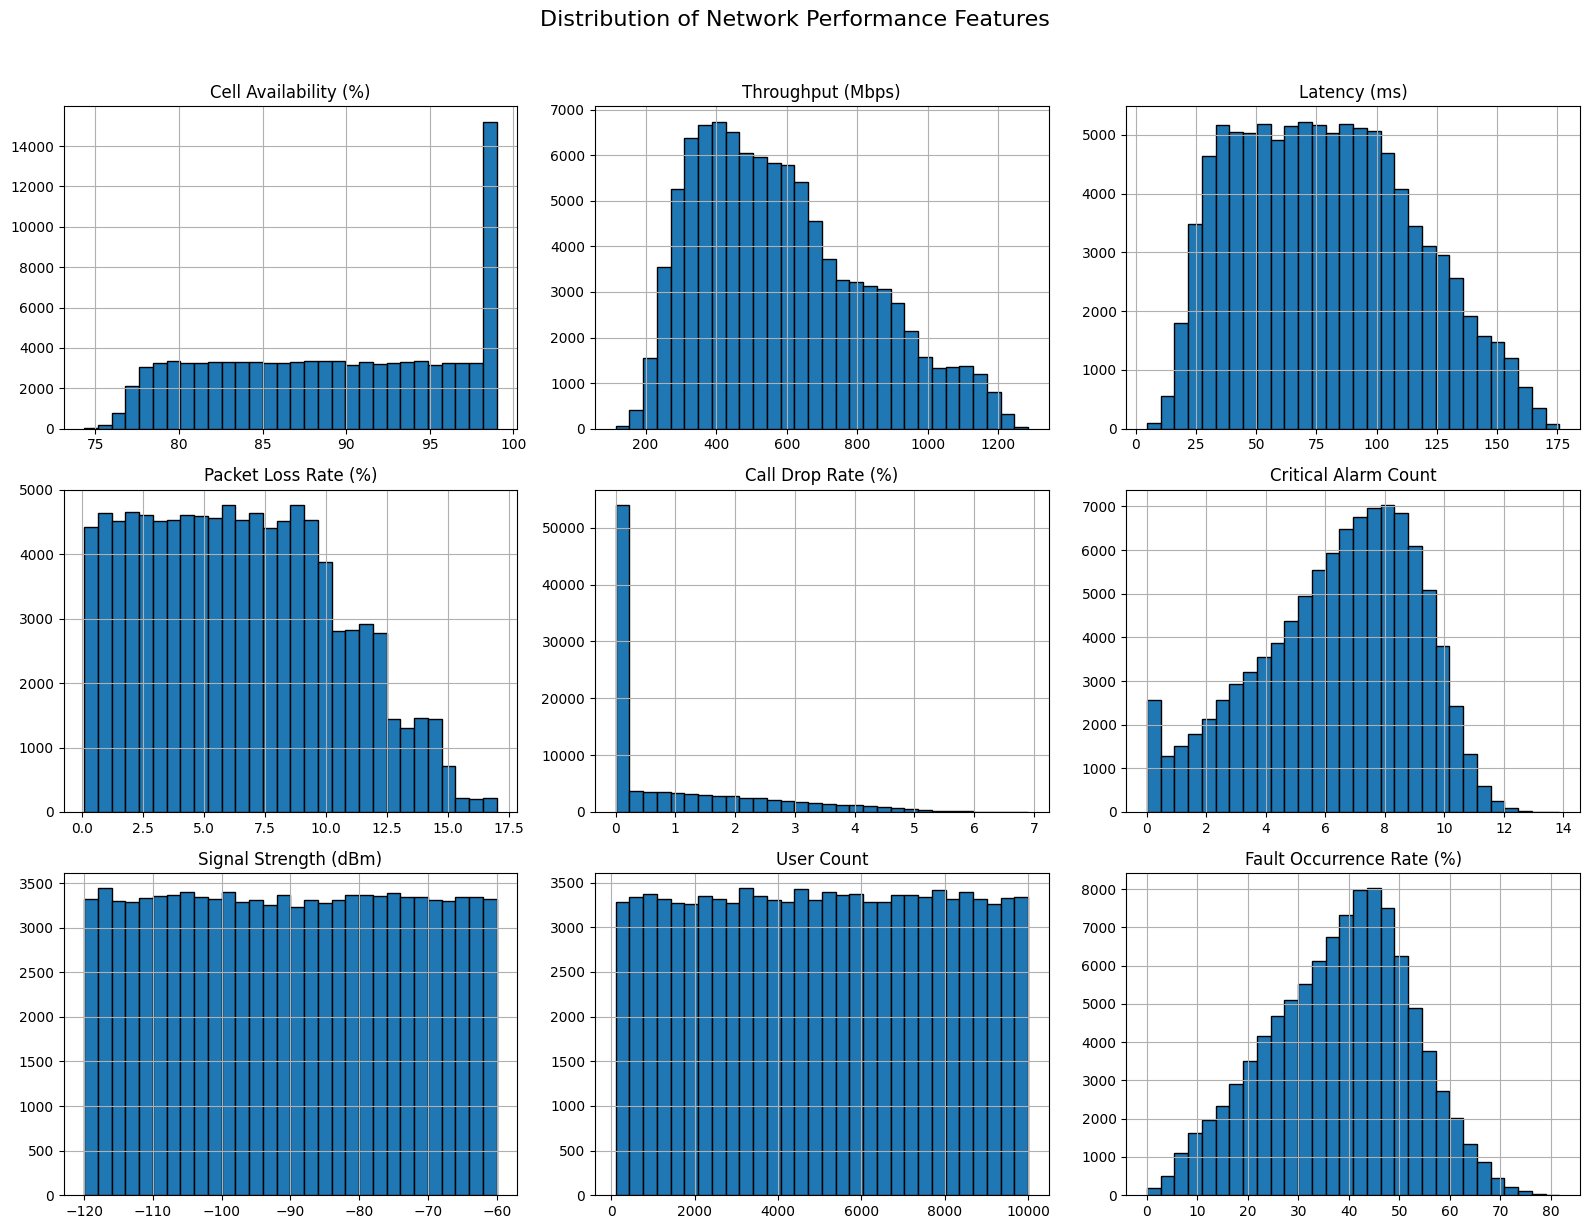

In [ ]:
import matplotlib.pyplot as plt

# Histograms for selected numerical features
df[plot_cols].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor='black'
)

plt.suptitle(
    'Distribution of Network Performance Features',
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

*(boxplots)*

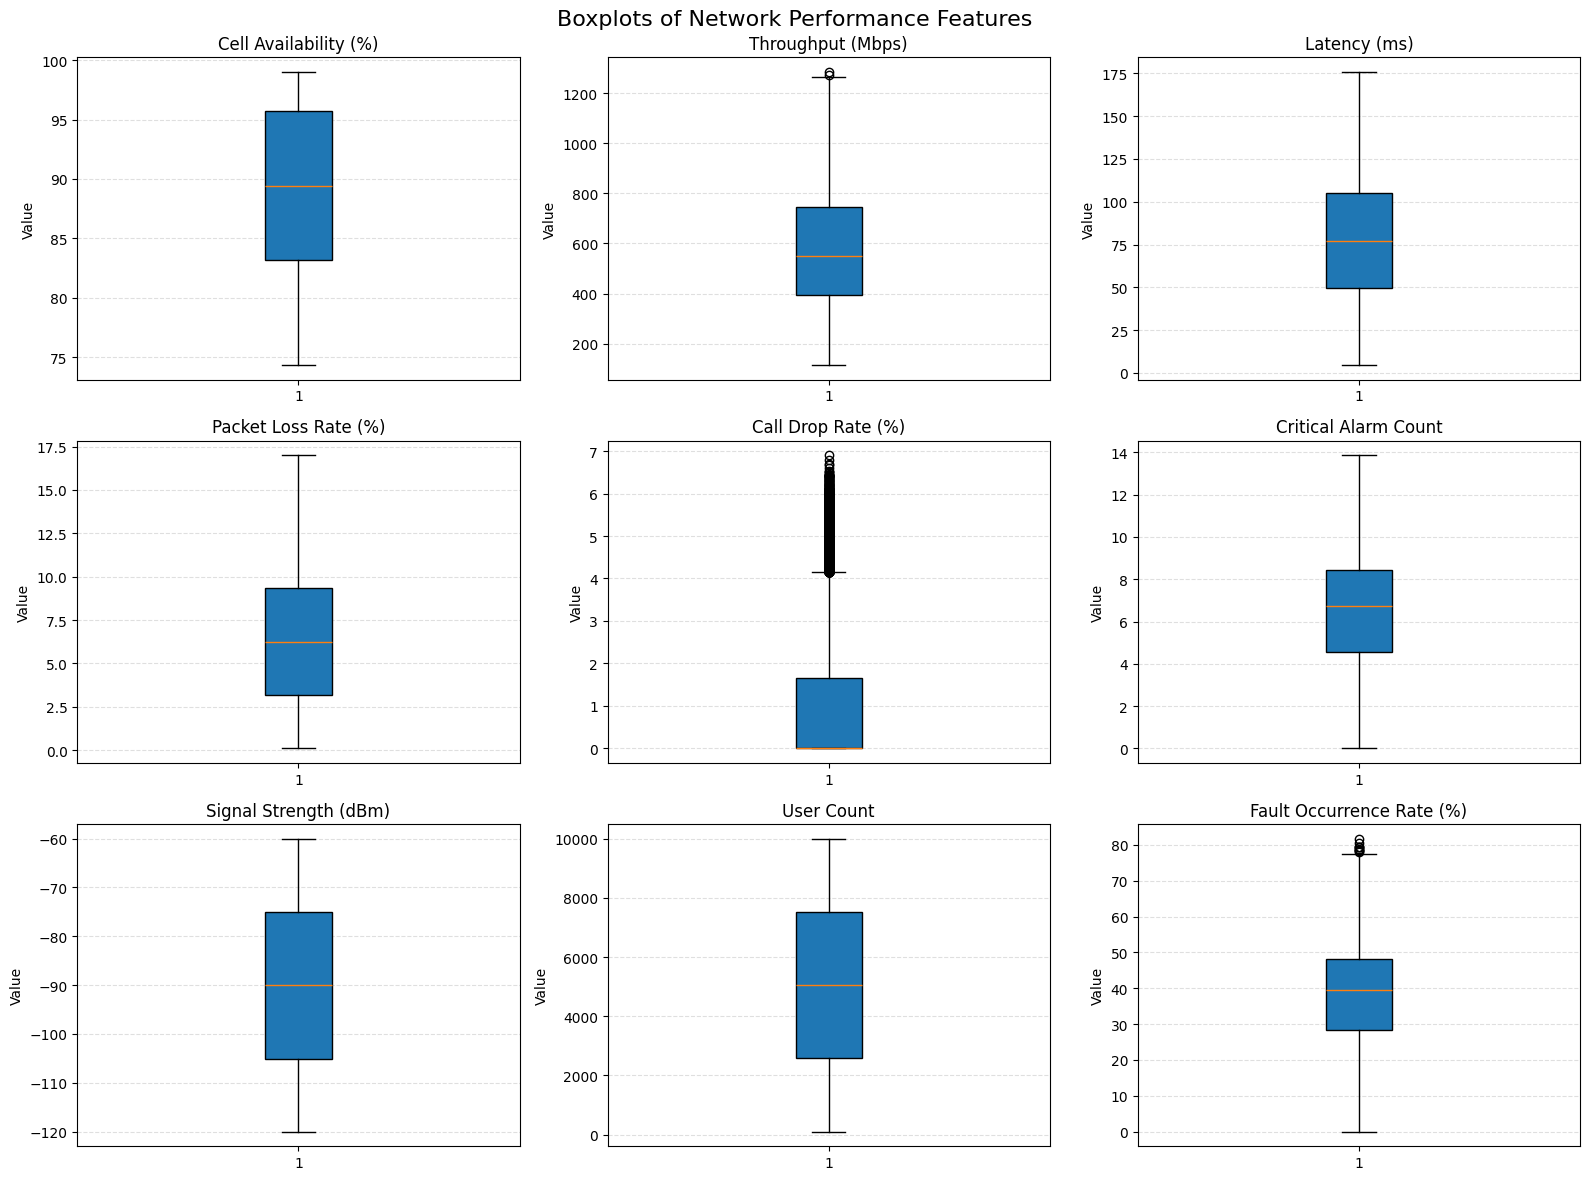

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for ax, col in zip(axes.flat, plot_cols):
    ax.boxplot(df[col].dropna(), patch_artist=True)
    ax.set_title(col)
    ax.set_ylabel('Value')
    ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.suptitle(
    'Boxplots of Network Performance Features',
    fontsize=16
)

plt.tight_layout()
plt.show()

*(scatter plot)*

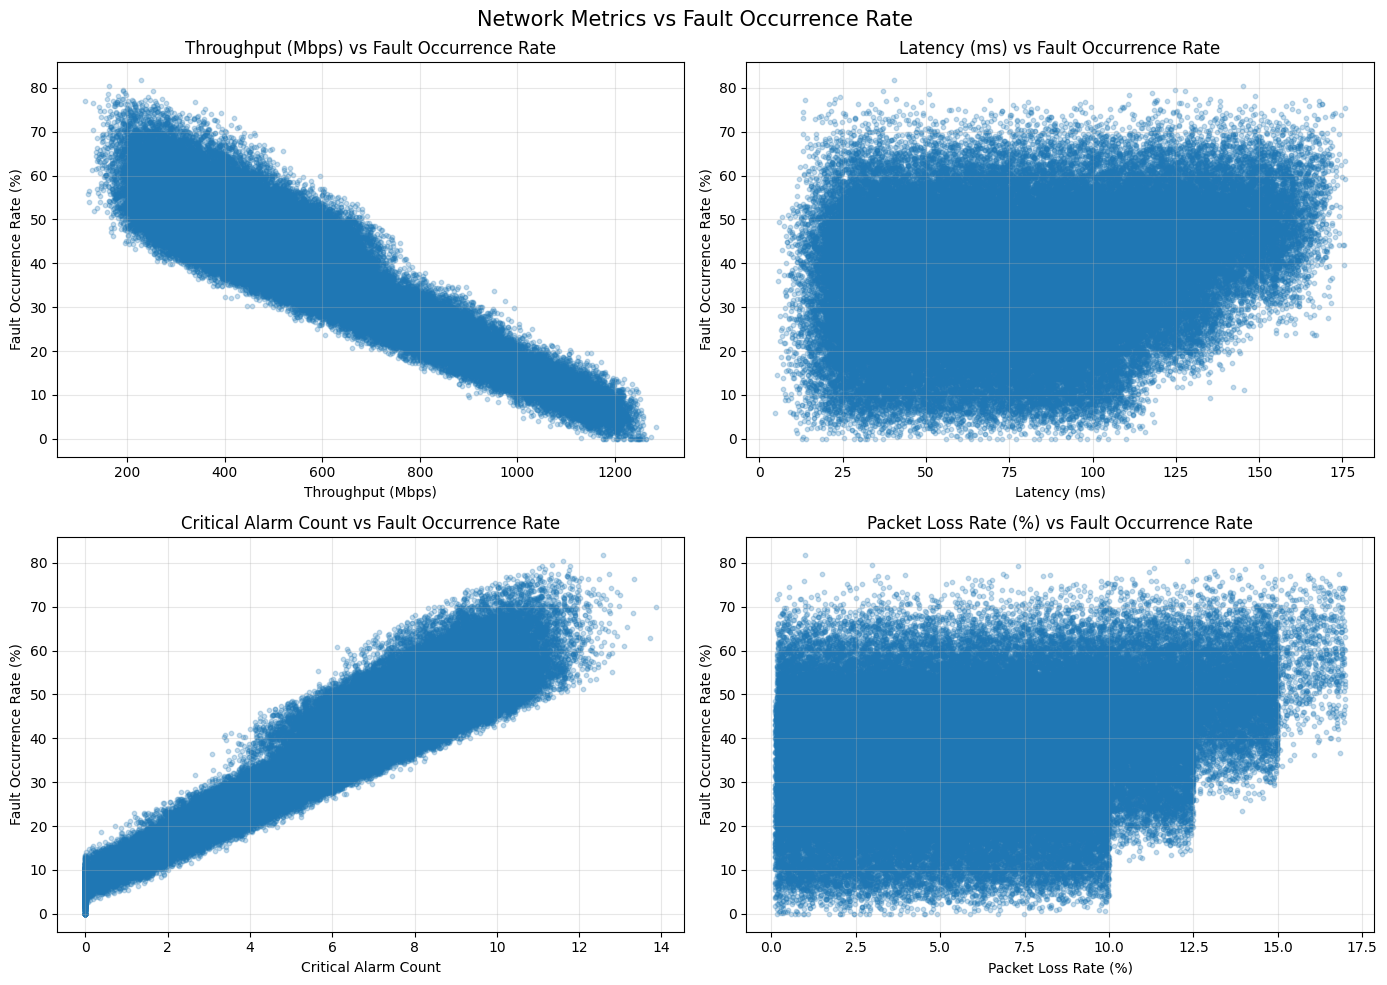

In [ ]:
import matplotlib.pyplot as plt

target = 'Fault Occurrence Rate (%)'

scatter_features = [
    'Throughput (Mbps)',
    'Latency (ms)',
    'Critical Alarm Count',
    'Packet Loss Rate (%)'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, feature in zip(axes.flat, scatter_features):
    ax.scatter(
        df[feature],
        df[target],
        alpha=0.25,
        s=10
    )

    ax.set_xlabel(feature)
    ax.set_ylabel(target)
    ax.set_title(f'{feature} vs Fault Occurrence Rate')
    ax.grid(alpha=0.3)

plt.suptitle(
    'Network Metrics vs Fault Occurrence Rate',
    fontsize=15
)

plt.tight_layout()
plt.show()

*(correlation heatmap)*

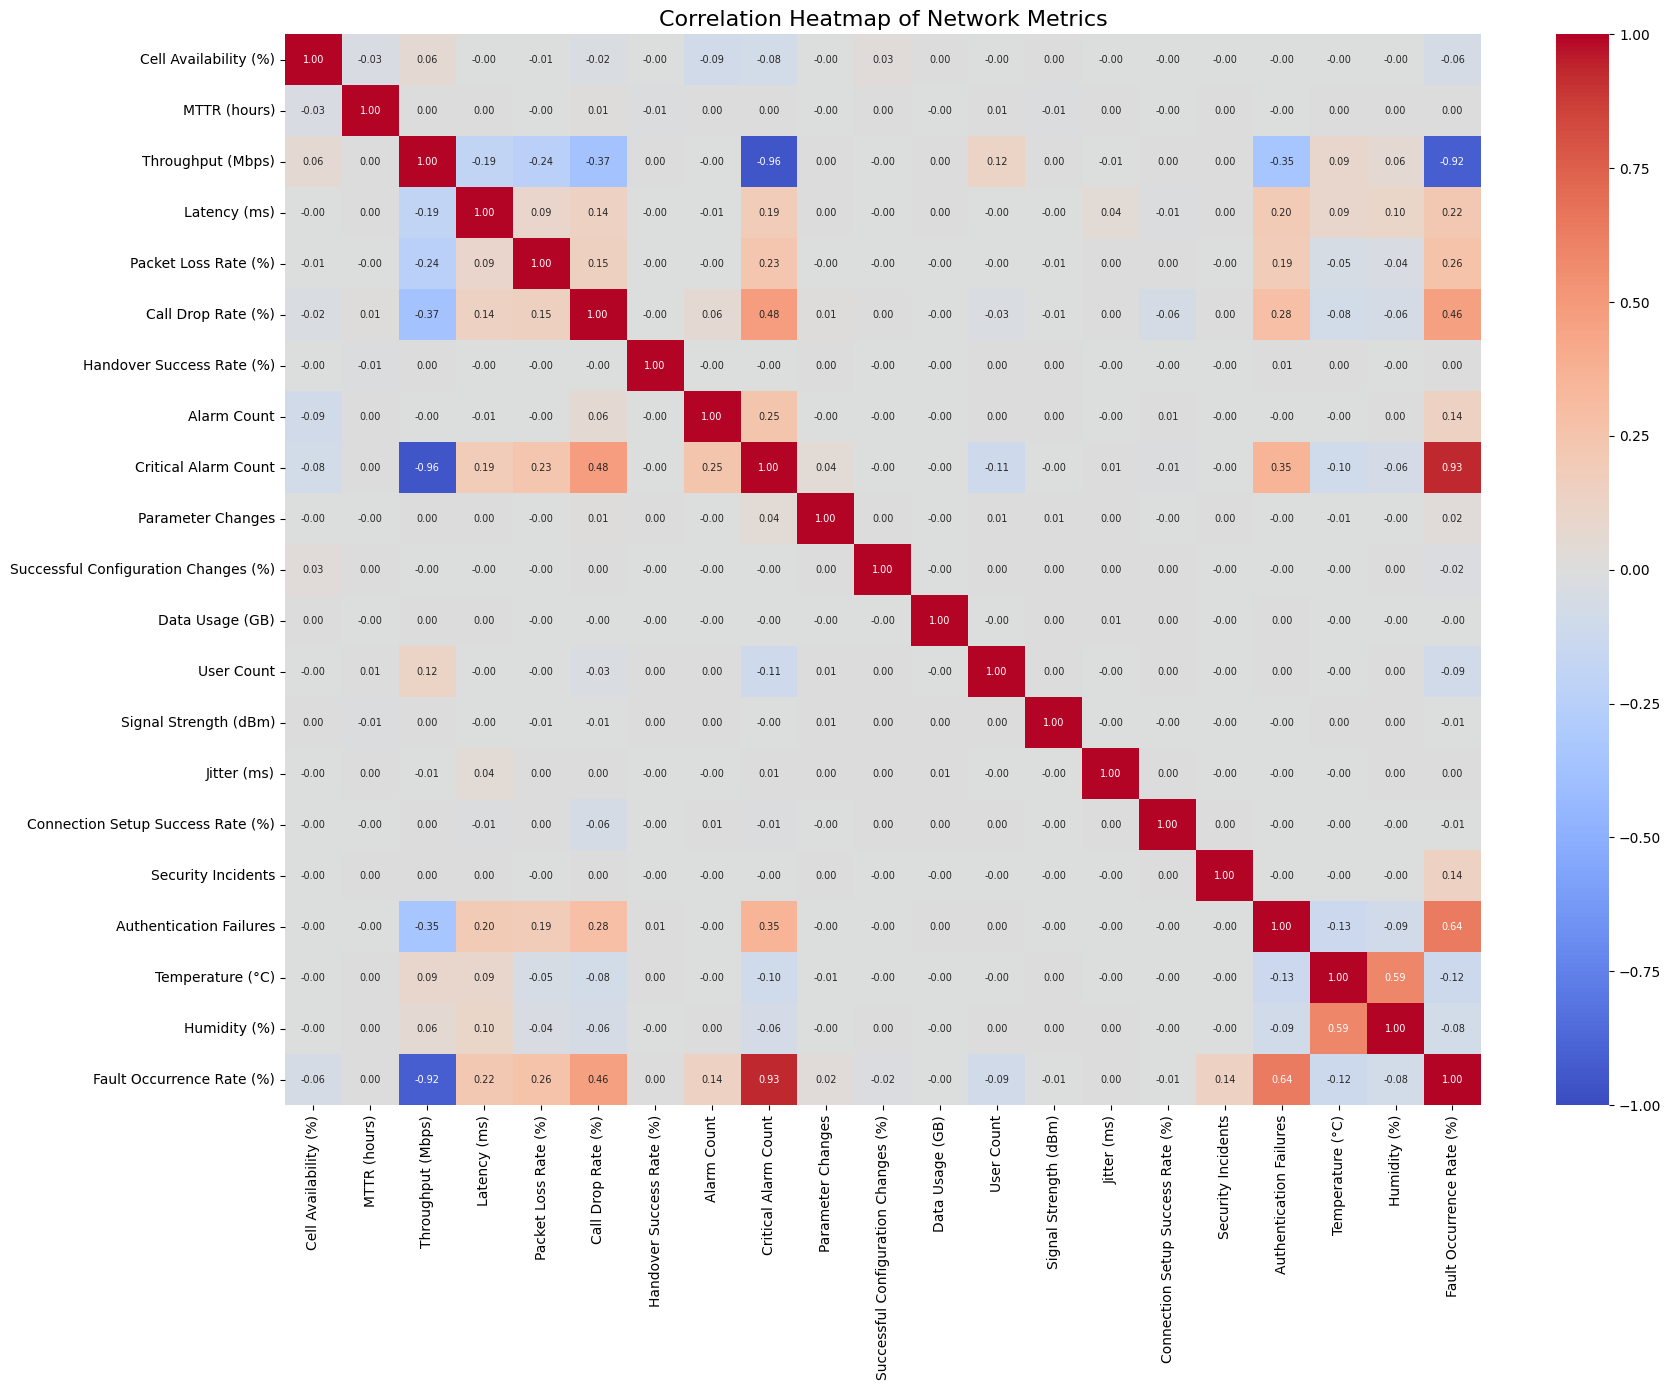

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Exclude ZIP because it is a location identifier
corr_cols = [
    col for col in measurement_cols
    if col != 'Zip'
]

correlation_matrix = df[corr_cols].corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 7}
)

plt.title('Correlation Heatmap of Network Metrics', fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# Inspect the strongest correlations with the target
target = 'Fault Occurrence Rate (%)'

target_corr = (
    df[corr_cols]
    .corr()[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

display(target_corr.to_frame('Correlation with Target'))

,Correlation with Target
Critical Alarm Count,0.930
Throughput (Mbps),-0.917
Authentication Failures,0.635
Call Drop Rate (%),0.463
Packet Loss Rate (%),0.259
Latency (ms),0.224
Security Incidents,0.139
Alarm Count,0.136
Temperature (°C),-0.121
User Count,-0.092


In [ ]:
# Inspect the strongest relationships more closely

features_to_check = [
    'Throughput (Mbps)',
    'Critical Alarm Count',
    'Authentication Failures'
]

for feature in features_to_check:
    print(f"\n{feature}")

    display(
        df.groupby(
            pd.qcut(df[feature], q=10, duplicates='drop')
        )['Fault Occurrence Rate (%)']
        .agg(['count', 'mean', 'median', 'std'])
        .round(3)
    )


Throughput (Mbps)


/tmp/ipykernel_952/2153428110.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(


,count,mean,median,std
Throughput (Mbps),,,,
"(114.991, 304.248]",10000,56.090,55.116,7.232
"(304.248, 365.113]",10000,51.165,49.843,6.620
"(365.113, 423.224]",10000,48.248,47.015,6.589
"(423.224, 483.954]",10000,45.454,44.219,6.431
"(483.954, 549.212]",10000,42.066,40.955,6.111
"(549.212, 616.3]",10000,38.908,37.931,5.881
"(616.3, 692.699]",10000,34.976,34.068,5.646
"(692.699, 805.273]",10000,28.865,28.517,4.513
"(805.273, 934.895]",10000,22.750,22.637,3.955



Critical Alarm Count


/tmp/ipykernel_952/2153428110.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(


,count,mean,median,std
Critical Alarm Count,,,,
"(-0.001, 2.456]",10000,12.952,13.127,4.905
"(2.456, 3.969]",10000,22.613,22.483,3.623
"(3.969, 5.107]",10000,29.021,28.464,4.442
"(5.107, 5.986]",10000,34.548,33.596,5.110
"(5.986, 6.745]",10000,38.604,37.529,5.406
"(6.745, 7.434]",10000,42.014,40.862,5.626
"(7.434, 8.093]",10000,45.225,43.923,5.853
"(8.093, 8.759]",10000,48.241,46.946,5.989
"(8.759, 9.565]",10000,51.604,50.259,6.210



Authentication Failures


/tmp/ipykernel_952/2153428110.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(


,count,mean,median,std
Authentication Failures,,,,
"(-0.001, 1.0]",13011,31.491,33.366,12.263
"(1.0, 3.0]",9340,28.722,29.122,11.901
"(3.0, 5.0]",12370,32.551,34.048,12.151
"(5.0, 6.0]",6311,31.106,31.654,11.655
"(6.0, 8.0]",9922,31.714,32.367,12.401
"(8.0, 10.0]",9415,35.850,37.471,11.509
"(10.0, 15.0]",10033,40.529,41.382,9.653
"(15.0, 21.0]",10178,42.128,42.969,9.868
"(21.0, 35.0]",10679,51.254,51.447,7.129


*(validate the target)*

In [ ]:
import numpy as np
import pandas as pd

target = 'Fault Occurrence Rate (%)'
assert target in df.columns, f"Target column not found: {target}"

print("Target data type:", df[target].dtype)
print("Missing target values:", df[target].isna().sum())
print("Infinite target values:", np.isinf(df[target]).sum())
print("Target minimum:", df[target].min())
print("Target maximum:", df[target].max())
print("Unique target values:", df[target].nunique())

display(df[target].describe().to_frame('Target Summary'))

Target data type: float64
Missing target values: 0
Infinite target values: 0
Target minimum: 0.0
Target maximum: 81.72103183839168
Unique target values: 99976


,Target Summary
count,100000.000
mean,38.163
std,14.035
min,0.000
25%,28.339
50%,39.455
75%,48.152
max,81.721


In [ ]:
# Exclude the target and high-cardinality location identifiers.
# Exclude "Issue Reported" until its meaning is verified.
excluded_cols = [
    'Fault Occurrence Rate (%)',
    'Zip',
    'City',
    'State',
    'Issue Reported'
]

feature_cols = [col for col in df.columns if col not in excluded_cols]

X = df[feature_cols].copy()
y = df[target].copy()

print("Number of input features:", X.shape[1])
print("Target:", target)
print("Categorical predictors:",
      X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist())
print("Numerical predictors:",
      X.select_dtypes(include=np.number).columns.tolist())

display(X.head())

Number of input features: 22
Target: Fault Occurrence Rate (%)
Categorical predictors: ['Season', 'Weather']
Numerical predictors: ['Cell Availability (%)', 'MTTR (hours)', 'Throughput (Mbps)', 'Latency (ms)', 'Packet Loss Rate (%)', 'Call Drop Rate (%)', 'Handover Success Rate (%)', 'Alarm Count', 'Critical Alarm Count', 'Parameter Changes', 'Successful Configuration Changes (%)', 'Data Usage (GB)', 'User Count', 'Signal Strength (dBm)', 'Jitter (ms)', 'Connection Setup Success Rate (%)', 'Security Incidents', 'Authentication Failures', 'Temperature (°C)', 'Humidity (%)']


,Season,Cell Availability (%),MTTR (hours),Throughput (Mbps),Latency (ms),Packet Loss Rate (%),Call Drop Rate (%),Handover Success Rate (%),Alarm Count,Critical Alarm Count,Parameter Changes,Successful Configuration Changes (%),Data Usage (GB),User Count,Signal Strength (dBm),Jitter (ms),Connection Setup Success Rate (%),Security Incidents,Authentication Failures,Temperature (°C),Humidity (%),Weather
0,Winter,98.045,3.000,653.531,74.336,6.438,1.467,99.290,13,6.718,18,91.850,47.490,2442,-110.120,15.670,99.000,8,2,-6.750,28.790,Clouds
1,Fall,99.000,8.850,719.299,90.651,5.180,0.022,96.500,12,5.551,17,90.370,47.930,2146,-77.960,37.310,94.860,11,4,10.360,37.040,Clear
2,Winter,99.000,6.110,868.787,78.068,8.688,0.000,96.790,5,1.898,2,95.280,44.680,1453,-114.570,8.500,96.610,1,10,-7.410,27.760,Clouds
3,Fall,95.333,7.660,332.074,32.318,6.200,1.979,99.120,7,8.715,12,98.590,22.150,5390,-68.550,34.350,95.950,4,1,14.800,34.090,Clear
4,Fall,99.000,2.820,658.490,84.256,11.800,0.190,91.400,11,6.013,18,97.800,25.800,7075,-66.000,24.200,92.640,6,0,13.090,32.050,Clouds


*(train-test split)*

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print(f"\nTraining records: {len(X_train):,} (80%)")
print(f"Testing records:  {len(X_test):,} (20%)")

Training features: (80000, 22)
Testing features: (20000, 22)
Training target: (80000,)
Testing target: (20000,)

Training records: 80,000 (80%)
Testing records:  20,000 (20%)


*(encoding + scaling)*

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Identify column types from the training data
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

print("Numerical features to scale:", len(numeric_features))
print("Categorical features to encode:", len(categorical_features))
print("Numerical columns:", numeric_features)
print("Categorical columns:", categorical_features)

Numerical features to scale: 20
Categorical features to encode: 2
Numerical columns: ['Cell Availability (%)', 'MTTR (hours)', 'Throughput (Mbps)', 'Latency (ms)', 'Packet Loss Rate (%)', 'Call Drop Rate (%)', 'Handover Success Rate (%)', 'Alarm Count', 'Critical Alarm Count', 'Parameter Changes', 'Successful Configuration Changes (%)', 'Data Usage (GB)', 'User Count', 'Signal Strength (dBm)', 'Jitter (ms)', 'Connection Setup Success Rate (%)', 'Security Incidents', 'Authentication Failures', 'Temperature (°C)', 'Humidity (%)']
Categorical columns: ['Season', 'Weather']


In [ ]:
# Learn scaling and encoding parameters from training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed.")
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Preprocessing completed.
Processed training shape: (80000, 28)
Processed testing shape: (20000, 28)
Training target shape: (80000,)
Testing target shape: (20000,)


*(Final preprocessing validation)*

In [ ]:
# Check missing values before preprocessing
print("Missing values in X_train:", X_train.isna().sum().sum())
print("Missing values in X_test:", X_test.isna().sum().sum())
print("Missing values in y_train:", y_train.isna().sum())
print("Missing values in y_test:", y_test.isna().sum())

# Check for infinite values
print("Infinite values in X_train:",
      np.isinf(X_train.select_dtypes(include=np.number)).sum().sum())

print("Infinite values in X_test:",
      np.isinf(X_test.select_dtypes(include=np.number)).sum().sum())

# Confirm original dataset remains unchanged
print("Original dataset shape:", df_raw.shape)
print("Original dataset still has 27 columns:", df_raw.shape[1] == 27)

# Confirm the processed matrices are finite
if hasattr(X_train_processed, "data") and hasattr(X_train_processed, "tocsr"):
    train_values = X_train_processed.data
    test_values = X_test_processed.data
else:
    train_values = np.asarray(X_train_processed)
    test_values = np.asarray(X_test_processed)

print("Processed training values are finite:",
      np.isfinite(train_values).all())

print("Processed testing values are finite:",
      np.isfinite(test_values).all())

Missing values in X_train: 0
Missing values in X_test: 0
Missing values in y_train: 0
Missing values in y_test: 0
Infinite values in X_train: 0
Infinite values in X_test: 0
Original dataset shape: (100000, 27)
Original dataset still has 27 columns: True
Processed training values are finite: True
Processed testing values are finite: True


*(save the preprocessed data and pipeline)*

In [ ]:
import joblib

joblib.dump(preprocessor, 'telecom_preprocessor.joblib')

joblib.dump(
    {
        'X_train': X_train_processed,
        'X_test': X_test_processed,
        'y_train': y_train,
        'y_test': y_test,
        'feature_cols': feature_cols,
        'target': target
    },
    'telecom_preprocessed_data.joblib'
)

print("Saved preprocessing pipeline and processed datasets.")

Saved preprocessing pipeline and processed datasets.
